In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('airline_tweets.csv')

print("Dataset Loaded Successfully!")

df.head()

Dataset Loaded Successfully!


,text,airline_sentiment,airline
0,@VirginAmerica What @dhepburn said.,neutral,Virgin America
1,@VirginAmerica plus you've added commercials t...,positive,Virgin America
2,@VirginAmerica I didn't today... Must mean I n...,neutral,Virgin America
3,@VirginAmerica it's really aggressive to blast...,negative,Virgin America
4,@VirginAmerica and it's a really big bad thing...,negative,Virgin America


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (14640, 3)


In [5]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['text', 'airline_sentiment', 'airline'], dtype='object')


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14640 entries, 0 to 14639
Data columns (total 3 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   text               14640 non-null  object
 1   airline_sentiment  14640 non-null  object
 2   airline            14640 non-null  object
dtypes: object(3)
memory usage: 343.3+ KB


In [7]:
print("Human Sentiment Labels:")
print(df['airline_sentiment'].value_counts())

Human Sentiment Labels:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [8]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
text                 0
airline_sentiment    0
airline              0
dtype: int64


In [9]:
!pip install vaderSentiment

In [10]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER Analyzer Initialized Successfully!")

VADER Analyzer Initialized Successfully!


In [11]:
def get_sentiment(text):

    score = analyzer.polarity_scores(str(text))['compound']

    if score >= 0.05:
        return 'positive'

    elif score <= -0.05:
        return 'negative'

    else:
        return 'neutral'

In [12]:
df['vader_sentiment'] = df['text'].apply(get_sentiment)

print("Sentiment Analysis Completed!")

Sentiment Analysis Completed!


In [13]:
df[['text', 'vader_sentiment']].head(10)

,text,vader_sentiment
0,@VirginAmerica What @dhepburn said.,neutral
1,@VirginAmerica plus you've added commercials t...,neutral
2,@VirginAmerica I didn't today... Must mean I n...,neutral
3,@VirginAmerica it's really aggressive to blast...,negative
4,@VirginAmerica and it's a really big bad thing...,negative
5,@VirginAmerica seriously would pay $30 a fligh...,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",positive
7,@VirginAmerica Really missed a prime opportuni...,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",positive
9,"@VirginAmerica it was amazing, and arrived an ...",positive


In [14]:
df['compound_score'] = df['text'].apply(
    lambda text: analyzer.polarity_scores(str(text))['compound']
)

df[['text', 'compound_score', 'vader_sentiment']].head(10)

,text,compound_score,vader_sentiment
0,@VirginAmerica What @dhepburn said.,0.0000,neutral
1,@VirginAmerica plus you've added commercials t...,0.0000,neutral
2,@VirginAmerica I didn't today... Must mean I n...,0.0000,neutral
3,@VirginAmerica it's really aggressive to blast...,-0.2716,negative
4,@VirginAmerica and it's a really big bad thing...,-0.5829,negative
5,@VirginAmerica seriously would pay $30 a fligh...,-0.5945,negative
6,"@VirginAmerica yes, nearly every time I fly VX...",0.6908,positive
7,@VirginAmerica Really missed a prime opportuni...,0.0790,positive
8,"@virginamerica Well, I didn't…but NOW I DO! :-D",0.7525,positive
9,"@VirginAmerica it was amazing, and arrived an ...",0.7717,positive


In [15]:
vader_counts = df['vader_sentiment'].value_counts()

print("VADER Sentiment Counts:")
print(vader_counts)

VADER Sentiment Counts:
vader_sentiment
positive    7615
negative    4464
neutral     2561
Name: count, dtype: int64


In [16]:
vader_percentage = (
    df['vader_sentiment'].value_counts(normalize=True) * 100
)

print("Sentiment Percentages:")
print(vader_percentage.round(2))

Sentiment Percentages:
vader_sentiment
positive    52.02
negative    30.49
neutral     17.49
Name: proportion, dtype: float64


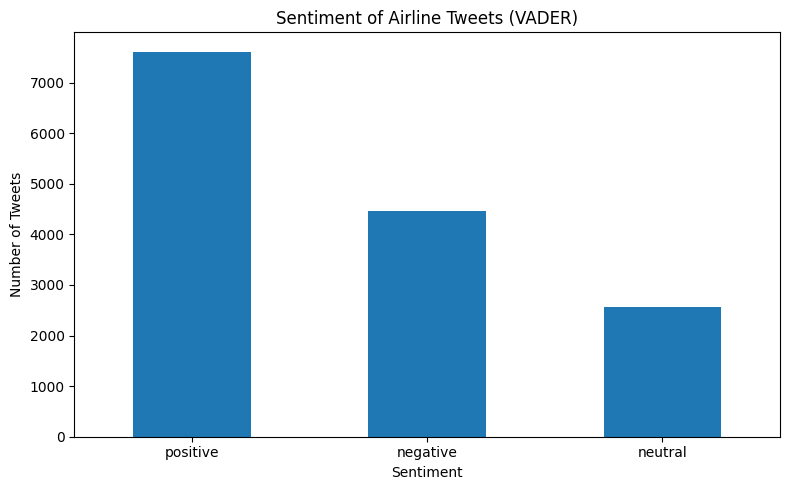

In [17]:
plt.figure(figsize=(8, 5))

df['vader_sentiment'].value_counts().plot(
    kind='bar'
)

plt.title('Sentiment of Airline Tweets (VADER)')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

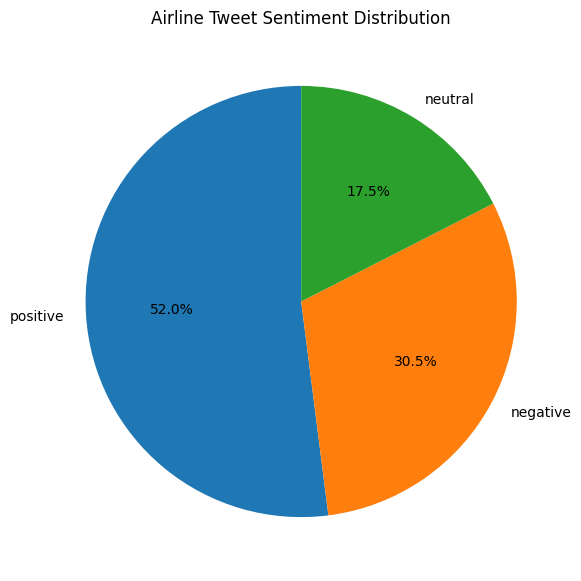

In [18]:
plt.figure(figsize=(7, 7))

df['vader_sentiment'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Airline Tweet Sentiment Distribution')
plt.ylabel('')
plt.show()

In [19]:
print("Human Sentiment Counts:")

print(df['airline_sentiment'].value_counts())

Human Sentiment Counts:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64


In [20]:
comparison = pd.DataFrame({
    'Human Labels': df['airline_sentiment'].value_counts(),
    'VADER Labels': df['vader_sentiment'].value_counts()
})

print(comparison)

          Human Labels  VADER Labels
negative          9178          4464
neutral           3099          2561
positive          2363          7615


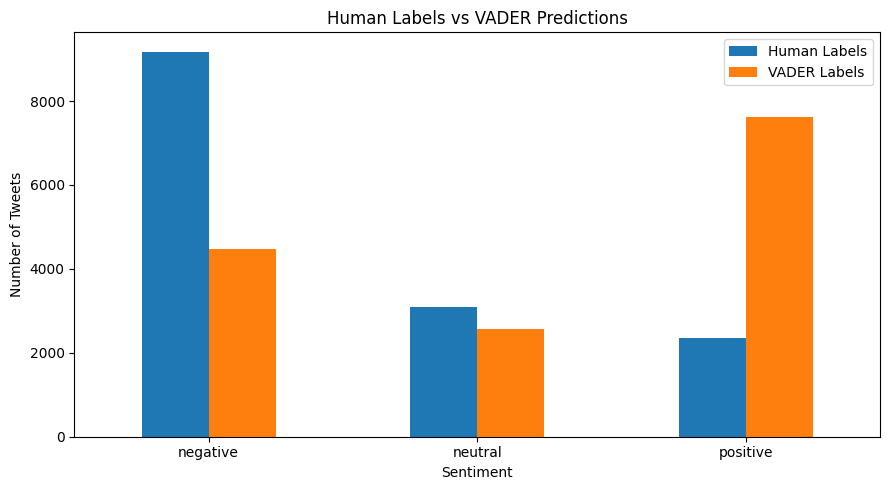

In [21]:
comparison.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Human Labels vs VADER Predictions')
plt.xlabel('Sentiment')
plt.ylabel('Number of Tweets')

plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [22]:
mismatch = df[
    df['vader_sentiment'] != df['airline_sentiment']
]

print("Total Mismatched Tweets:", len(mismatch))

display(
    mismatch[
        ['text', 'airline_sentiment', 'vader_sentiment']
    ].head(10)
)

Total Mismatched Tweets: 7468


,text,airline_sentiment,vader_sentiment
1,@VirginAmerica plus you've added commercials t...,positive,neutral
7,@VirginAmerica Really missed a prime opportuni...,neutral,positive
10,@VirginAmerica did you know that suicide is th...,neutral,negative
16,@VirginAmerica So excited for my first cross c...,positive,negative
17,@VirginAmerica I flew from NYC to SFO last we...,negative,positive
20,@VirginAmerica why are your first fares in May...,negative,neutral
23,@VirginAmerica will you be making BOS&gt;LAS n...,neutral,negative
24,@VirginAmerica you guys messed up my seating.....,negative,positive
27,@VirginAmerica do you miss me? Don't worry we'...,neutral,positive
28,@VirginAmerica amazing to me that we can't get...,negative,positive


In [23]:
positive_words = [
    'amazing',
    'great',
    'thanks',
    'wonderful',
    'awesome'
]

sarcastic_examples = mismatch[
    mismatch['text'].str.lower().str.contains(
        '|'.join(positive_words),
        na=False
    )
]

display(
    sarcastic_examples[
        ['text', 'airline_sentiment', 'vader_sentiment']
    ].head(10)
)

,text,airline_sentiment,vader_sentiment
16,@VirginAmerica So excited for my first cross c...,positive,negative
28,@VirginAmerica amazing to me that we can't get...,negative,positive
50,@VirginAmerica Is flight 769 on it's way? Was ...,neutral,negative
62,@VirginAmerica @ladygaga @carrieunderwood all ...,neutral,positive
77,@VirginAmerica first time flying you all. do y...,neutral,positive
106,@VirginAmerica called your service line and wa...,negative,positive
142,@VirginAmerica Can you find us a flt out of LA...,neutral,positive
186,"@VirginAmerica a lot of ""apologies"" being thro...",negative,positive
219,@VirginAmerica I did it but there was a proble...,negative,positive
336,@VirginAmerica Many Thanks for the Follow.\n#o...,neutral,positive


In [24]:
print("========== FINAL SENTIMENT ANALYSIS ==========")

print("\nHuman Sentiment Counts:")
print(df['airline_sentiment'].value_counts())

print("\nVADER Sentiment Counts:")
print(df['vader_sentiment'].value_counts())

print("\nTotal Tweets:", len(df))

print("\nTotal Mismatches:", len(mismatch))

print("\nMismatch Percentage:",
      round(len(mismatch) / len(df) * 100, 2), "%")

========== FINAL SENTIMENT ANALYSIS ==========

Human Sentiment Counts:
airline_sentiment
negative    9178
neutral     3099
positive    2363
Name: count, dtype: int64

VADER Sentiment Counts:
vader_sentiment
positive    7615
negative    4464
neutral     2561
Name: count, dtype: int64

Total Tweets: 14640

Total Mismatches: 7468

Mismatch Percentage: 51.01 %


In [26]:
df.to_csv('airline_sentiment_results.csv', index=False)

from google.colab import files

files.download('airline_sentiment_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>